# 03 · Anomaly detection, incidents and the supervised reference (M5, M6)

CRISP-DM modeling: Isolation Forest, LOF and PCA error per log type, percentile calibration, the ensemble, and incidents, for `russellmitchell` (dev) and `santos` (test). Sections 11 to 17 add the supervised reference of M6.

`logtriage detect` reads no ground truth. This notebook does, through `logtriage.eval`, to score what `detect` wrote. `q` and `gap_minutes` were chosen on russellmitchell only and are reused unchanged on santos. Nothing below feeds back into them, and the unclipped variant in §6 is used for no selection.

These are M5 numbers. The frozen targets of `reports/targets.md` are scored for the record in M11.

In [1]:
import json
import os
from pathlib import Path

if Path.cwd().name == "notebooks":  # DuckDB views use paths relative to the repository root
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from logtriage.config import DEV_TESTBED, TEST_TESTBED, load_settings
from logtriage.eval import eda, viz
from logtriage.eval.detection import (
    anomalous_by_hour,
    embedding_inputs,
    evaluate,
    truth_context,
)
from logtriage.eval.metrics import required_detections
from logtriage.ml.detect import (
    DETECT_REPORT_FILE,
    INCIDENTS_FILE,
    SCORES_FILE,
    detect,
    score_testbed,
)

TESTBEDS = [DEV_TESTBED, TEST_TESTBED]
settings = load_settings()
figures = settings.paths.reports_dir / "figures"
directories = {name: settings.paths.processed_dir / name for name in TESTBEDS}
reports = {
    name: json.loads((path / DETECT_REPORT_FILE).read_text(encoding="utf-8"))
    for name, path in directories.items()
}
scores = {name: pd.read_parquet(path / SCORES_FILE) for name, path in directories.items()}
incidents = {name: pd.read_parquet(path / INCIDENTS_FILE) for name, path in directories.items()}
periods = {name: eda.testbed_periods(name, settings) for name in TESTBEDS}
contexts, intervals = {}, {}
for name in TESTBEDS:
    with eda.connect(name, settings) as con:
        contexts[name] = truth_context(
            con, periods[name], list(reports[name]["log_types"]), settings
        )
        intervals[name] = eda.phase_intervals(con)
results = {name: evaluate(scores[name], len(incidents[name]), contexts[name]) for name in TESTBEDS}


def show(title: str, frame: pd.DataFrame) -> None:
    """Display a table under a heading."""
    display(Markdown(f"**{title}**"))
    display(frame)

## 1. Choice of `q` and `gap_minutes` on russellmitchell

§6.5: the highest phase recall within 25 incidents per day, ties to fewer incidents. `logtriage.eval.tuning` wrote the grid below and the chosen values to `configs/default.yaml`. It has no way to reach santos.

An earlier run is discarded and logged (D31): plain LOF scored ordinary windows near 1e10, next to duplicated quiet windows, which capped real bursts. That was a defect, and it shows in raw training scores.

In [2]:
grid = pd.read_csv(settings.paths.reports_dir / "results" / "tuning_dev.csv")
grid["within_budget"] = grid["incidents_per_day"] <= settings.ml.incidents_per_day_budget
show(
    "Grid on russellmitchell",
    grid.drop(columns=["phases", "missed"]).round(3).set_index(["q", "gap_minutes"]),
)
display(Markdown(f"**Chosen:** `q = {settings.ml.q}`, `gap_minutes = {settings.ml.gap_minutes}`"))

**Grid on russellmitchell**

anomalous_windows  incidents  incidents_per_day  \
q     gap_minutes                                                    
0.950 5                          993        443            236.354   
      10                         993        305            162.727   
      15                         993        130             69.359   
      30                         993         91             48.551   
0.970 5                          763        419            223.549   
      10                         763        316            168.596   
      15                         763        136             72.560   
      30                         763         94             50.152   
0.980 5                          556        371            197.940   
      10                         556        308            164.328   
      15                         556        136             72.560   
      30                         556         96             51.219   
0.990 5                          181        144             76.828   
      10                         181        137             73.094   
      15                         181        135             72.027   
      30                         181        116             61.890   
0.995 5                          133        106             56.554   
      10                         133        106             56.554   
      15                         133        105             56.021   
      30                         133         99             52.820   
0.999 5                           24          9              4.802   
      10                          24          8              4.268   
      15                          24          8              4.268   
      30                          24          7              3.735   

                   phases_detected  phase_recall  within_budget  
q     gap_minutes                                                
0.950 5                          9           0.9          False  
      10                         9           0.9          False  
      15                         9           0.9          False  
      30                         9           0.9          False  
0.970 5                          9           0.9          False  
      10                         9           0.9          False  
      15                         9           0.9          False  
      30                         9           0.9          False  
0.980 5                          8           0.8          False  
      10                         8           0.8          False  
      15                         8           0.8          False  
      30                         8           0.8          False  
0.990 5                          7           0.7          False  
      10                         7           0.7          False  
      15                         7           0.7          False  
      30                         7           0.7          False  
0.995 5                          7           0.7          False  
      10                         7           0.7          False  
      15                         7           0.7          False  
      30                         7           0.7          False  
0.999 5                          6           0.6           True  
      10                         6           0.6           True  
      15                         6           0.6           True  
      30                         6           0.6           True

**Chosen:** `q = 0.999`, `gap_minutes = 30`

Only `q = 0.999` fits the budget. The next value down, 0.995, gives more than 50 incidents per day, mostly isolated `audit` windows, and the grid of §6.5 has nothing between them. So the chosen point uses a small part of the budget, on both testbeds.

## 2. Phase recall and incidents per day

The primary denominator is frozen in `reports/targets.md`. The secondary variant leaves out `dnsteal_exfil` (D16).

In [3]:
rows = []
for name in TESTBEDS:
    result = results[name]
    recall = result.recall
    rows.append(
        {
            "testbed": name,
            "phases_detected": f"{recall['detected']} of {recall['phases']}",
            "phase_recall": round(recall["recall"], 3),
            "needed_for_80%": required_detections(recall["phases"], 0.8),
            "without_exfil": f"{recall['detected_without_exfil']} of "
            f"{recall['phases_without_exfil']}",
            "recall_without_exfil": round(recall["recall_without_exfil"], 3),
            "incidents": result.incidents,
            "incidents_per_day": round(result.incidents_per_day, 2),
            "anomalous_eval_windows": reports[name]["anomalous_eval_windows"],
            "missed": ", ".join(recall["missed"]),
        }
    )
with pd.option_context("display.max_colwidth", None):
    show("Phase recall and incidents per day", pd.DataFrame(rows).set_index("testbed").T)

**Phase recall and incidents per day**

testbed,russellmitchell,santos
phases_detected,6 of 10,5 of 9
phase_recall,0.6,0.556
needed_for_80%,8,8
without_exfil,6 of 9,5 of 8
recall_without_exfil,0.667,0.625
incidents,7,3
incidents_per_day,3.73,1.11
anomalous_eval_windows,24,5
missed,"dnsteal, dnsteal_exfil, network_scans, service_stop","cracking, dnsteal_exfil, network_scans, service_stop"


Santos stays far inside the budget and well below the phase recall target of 8 of 9. This is the measured result of the frozen rule; it is not retuned.

## 3. Phase detection per log type

Each cell counts the anomalous windows in an incident that hold a labeled line of that phase, per log type (D29). `dns_only` would show a phase credited through DNS windows alone.

In [4]:
for name in TESTBEDS:
    show(f"{name}: phases per log type", results[name].credit)

**russellmitchell: phases per log type**

,apache_access,audit,detected,dns_only
phase,,,,
dnsteal_exfil,0,0,False,False
network_scans,0,0,False,False
service_scans,1,0,True,False
dirb,1,0,True,False
wpscan,2,0,True,False
webshell,2,0,True,False
cracking,1,0,True,False
privilege_escalation,0,1,True,False
service_stop,0,0,False,False


**santos: phases per log type**

,apache_access,audit,detected,dns_only
phase,,,,
dnsteal_exfil,0,0,False,False
service_stop,0,0,False,False
network_scans,0,0,False,False
service_scans,1,0,True,False
dirb,1,0,True,False
wpscan,1,0,True,False
webshell,1,0,True,False
cracking,0,0,False,False
privilege_escalation,0,1,True,False


## 4. Window metrics

Label-ambiguous windows are left out (D17). `dns` has its own row, because of the contaminated baseline (D16). `apache_error` has no baseline and no scores on either testbed, so it is reported as not detectable. Pooled recall is low because exfiltration windows are most attack windows.

In [5]:
for name in TESTBEDS:
    show(f"{name}: window metrics", results[name].windows.round(4))
    show(
        f"{name}: secondary, with label-ambiguous windows counted as normal",
        results[name].windows_with_ambiguous.loc[["pooled", "dns"]].round(4),
    )
    display(Markdown(f"Not detectable, no baseline: {', '.join(reports[name]['no_baseline'])}"))

**russellmitchell: window metrics**

,windows,attack,anomalous,true_positives,precision,recall,f1,pr_auc
scope,,,,,,,,
pooled,8813,2102,24,4,0.1667,0.0019,0.0038,0.1462
apache_access,3458,4,5,3,0.6000,0.7500,0.6667,0.5742
audit,1514,3,3,1,0.3333,0.3333,0.3333,0.2897
auth,1249,2,14,0,0.0000,0.0000,NaN,0.0662
dns,2435,2092,0,0,NaN,0.0000,NaN,0.7370
vpn,157,1,2,0,0.0000,0.0000,NaN,0.2000


**russellmitchell: secondary, with label-ambiguous windows counted as normal**

,windows,attack,anomalous,true_positives,precision,recall,f1,pr_auc
scope,,,,,,,,
pooled,11233,2102,24,4,0.1667,0.0019,0.0038,0.1209
dns,4855,2092,0,0,NaN,0.0000,NaN,0.3653


Not detectable, no baseline: apache_error

**santos: window metrics**

,windows,attack,anomalous,true_positives,precision,recall,f1,pr_auc
scope,,,,,,,,
pooled,13339,1454,5,3,0.6000,0.0021,0.0041,0.1168
apache_access,5632,4,3,2,0.6667,0.5000,0.5714,0.8167
audit,2730,2,2,1,0.5000,0.5000,0.5000,0.5053
auth,1798,1,0,0,NaN,0.0000,NaN,0.1250
dns,2952,1446,0,0,NaN,0.0000,NaN,0.3414
vpn,227,1,0,0,NaN,0.0000,NaN,0.2000


**santos: secondary, with label-ambiguous windows counted as normal**

,windows,attack,anomalous,true_positives,precision,recall,f1,pr_auc
scope,,,,,,,,
pooled,16336,1454,5,3,0.6,0.0021,0.0041,0.0854
dns,5949,1446,0,0,NaN,0.0000,NaN,0.1711


Not detectable, no baseline: apache_error

## 5. The `dnsteal_exfil` expectation

M5 recorded, before any result, that `dnsteal_exfil` may be hard to detect unsupervised on santos. Measured here: is an exfiltration window ranked above other DNS windows at all? The DNS PR-AUC is compared with the share of attack windows, which is what a score with no information would reach.

In [6]:
rows = []
for name in TESTBEDS:
    table = results[name].table
    dns = table[(table["log_type"] == "dns") & ~table["is_ambiguous"]]
    exfil = dns["phases"].map(lambda value: "dnsteal_exfil" in value)
    rows.append(
        {
            "testbed": name,
            "dns_windows": len(dns),
            "attack_share": round(dns["is_attack"].mean(), 3),
            "pr_auc": round(results[name].windows.loc["dns", "pr_auc"], 3),
            "median_score_exfil": round(dns.loc[exfil, "score"].median(), 3),
            "median_score_other": round(dns.loc[~exfil, "score"].median(), 3),
            "highest_score_exfil": round(dns.loc[exfil, "score"].max(), 4),
        }
    )
show("DNS windows on inet-firewall", pd.DataFrame(rows).set_index("testbed"))

**DNS windows on inet-firewall**

,dns_windows,attack_share,pr_auc,median_score_exfil,median_score_other,highest_score_exfil
testbed,,,,,,
russellmitchell,2435,0.859,0.737,0.473,0.811,0.9875
santos,2952,0.490,0.341,0.534,0.811,0.9867


The expectation holds on both testbeds. `dnsteal_exfil` is missed, and DNS PR-AUC is below the attack share, so the score ranks exfiltration windows worse than chance: they score lower than other DNS windows. The tunnel is the normal state of the training period (D16), and no unsupervised model fit there can call it new.

## 6. Secondary variant: without the one-sided clip

Same `q`, same gap, the models refit on unclipped features. Reported as D29 requires and **used for no selection**.

In [7]:
unclipped = {}
for name in TESTBEDS:
    scored = score_testbed(name, settings, clip=False)
    table, groups = detect(
        scored, settings.ml.q, settings.ml.gap_minutes, settings.features.window_seconds
    )
    unclipped[name] = evaluate(table, len(groups), contexts[name])
    show(f"{name}: unclipped, phases per log type", unclipped[name].credit)
rows = []
for name in TESTBEDS:
    for variant, result in (("primary (clipped)", results[name]), ("unclipped", unclipped[name])):
        dns = result.windows.loc["dns"]
        rows.append(
            {
                "testbed": name,
                "variant": variant,
                "phases": f"{result.recall['detected']} of {result.recall['phases']}",
                "phases_dns_only": int(result.credit["dns_only"].sum()),
                "incidents_per_day": round(result.incidents_per_day, 2),
                "dns_anomalous": int(dns["anomalous"]),
                "dns_true_positives": int(dns["true_positives"]),
                "dns_pr_auc": round(dns["pr_auc"], 3),
            }
        )
show("Clipped and unclipped", pd.DataFrame(rows).set_index(["testbed", "variant"]))

**russellmitchell: unclipped, phases per log type**

,apache_access,audit,detected,dns_only
phase,,,,
dnsteal_exfil,0,0,False,False
network_scans,0,0,False,False
service_scans,1,0,True,False
dirb,1,0,True,False
wpscan,2,0,True,False
webshell,2,0,True,False
cracking,1,0,True,False
privilege_escalation,0,1,True,False
service_stop,0,0,False,False


**santos: unclipped, phases per log type**

,apache_access,audit,dns,detected,dns_only
phase,,,,,
dnsteal_exfil,0,0,0,False,False
service_stop,0,0,0,False,False
network_scans,0,0,3,True,True
service_scans,1,0,1,True,False
dirb,1,0,0,True,False
wpscan,1,0,1,True,False
webshell,1,0,0,True,False
cracking,0,0,1,True,True
privilege_escalation,0,1,0,True,False


**Clipped and unclipped**

phases  phases_dns_only  \
testbed         variant                                       
russellmitchell primary (clipped)  6 of 10                0   
                unclipped          6 of 10                0   
santos          primary (clipped)   5 of 9                0   
                unclipped           7 of 9                2   

                                   incidents_per_day  dns_anomalous  \
testbed         variant                                               
russellmitchell primary (clipped)               3.73              0   
                unclipped                       7.47             17   
santos          primary (clipped)               1.11              0   
                unclipped                       1.11           1012   

                                   dns_true_positives  dns_pr_auc  
testbed         variant                                            
russellmitchell primary (clipped)                   0       0.737  
                unclipped                           0       0.679  
santos          primary (clipped)                   0       0.341  
                unclipped                           5       0.299

On santos the unclipped run scores more phases, and that gain is the false credit D29 warned about. The two extra phases come only through DNS, from about a thousand windows flagged after the tunnel stops at about 07:16 on 01-16, of which a handful hold a labeled line by coincidence of timing. Those windows mark the end of the tunnel, not the scans. The primary number stays the clipped one.

## 7. Calibration checks

D27 keeps the santos split and watches for daytime false alarms: this is the share of eval windows flagged per UTC hour. D28 widens thin references with out-of-fold fit scores.

In [8]:
for name in TESTBEDS:
    table = anomalous_by_hour(scores[name])
    show(
        f"{name}: hours with a flagged window (share of eval windows)", table[table.sum(axis=1) > 0]
    )
rows = []
for name in TESTBEDS:
    for log_type, entry in reports[name]["log_types"].items():
        rows.append(
            {
                "testbed": name,
                "log_type": log_type,
                "calib_windows": entry["calib_windows"],
                "thin": entry["thin"],
                "reference_size": entry["reference_size"],
                "references": ", ".join(sorted(set(entry["reference_by_host"].values()))),
                "pca_components": entry["pca_components"],
                "common_entities": len(entry["common_entities"]),
            }
        )
show("Calibration references", pd.DataFrame(rows).set_index(["testbed", "log_type"]))

**russellmitchell: hours with a flagged window (share of eval windows)**

log_type,apache_access,audit,auth,dns,vpn
hour_utc,,,,,
3,0.0320,0.0000,0.1639,0.0,0.0000
4,0.0083,0.0233,0.0000,0.0,0.0000
12,0.0000,0.0000,0.0189,0.0,0.0000
14,0.0000,0.0000,0.0000,0.0,0.2222
15,0.0000,0.0000,0.0189,0.0,0.0000
16,0.0000,0.0230,0.0345,0.0,0.0000


**santos: hours with a flagged window (share of eval windows)**

log_type,apache_access,audit,auth,dns,vpn
hour_utc,,,,,
8,0.0000,0.0064,0.0,0.0,0.0
11,0.0089,0.0048,0.0,0.0,0.0


**Calibration references**

calib_windows   thin  reference_size  \
testbed         log_type                                              
russellmitchell apache_access           1264  False            1264   
                audit                    209  False             209   
                auth                     272  False             272   
                dns                     1226  False            1226   
                vpn                       24   True             143   
santos          apache_access             83   True            1915   
                audit                    164   True            1157   
                auth                     176   True             868   
                dns                      750  False             750   
                vpn                        7   True              84   

                                   references  pca_components  common_entities  
testbed         log_type                                                        
russellmitchell apache_access  host, log_type               1                0  
                audit                log_type               4                0  
                auth                 log_type               2                1  
                dns                      host               5                0  
                vpn              log_type+oof               2                0  
santos          apache_access    log_type+oof               5                0  
                audit            log_type+oof               3                0  
                auth             log_type+oof               2                1  
                dns                      host               4                0  
                vpn              log_type+oof               1                0

## 8. Incidents

Sorted by priority (§6.6).

In [9]:
columns = [
    "incident_id",
    "start",
    "end",
    "hosts",
    "log_types",
    "n_windows",
    "max_score",
    "priority",
]
for name in TESTBEDS:
    table = incidents[name][columns].copy()
    table["hosts"] = table["hosts"].map(len)
    table["log_types"] = table["log_types"].map(", ".join)
    table[["max_score", "priority"]] = table[["max_score", "priority"]].round(4)
    show(f"{name}: incidents (hosts as a count)", table.set_index("incident_id"))

**russellmitchell: incidents (hosts as a count)**

,start,end,hosts,log_types,n_windows,max_score,priority
incident_id,,,,,,,
russellmitchell-0004,2022-01-24 03:56:00+00:00,2022-01-24 04:00:00+00:00,9,"apache_access, auth",13,1.0,1.1264
russellmitchell-0003,2022-01-23 15:56:00+00:00,2022-01-23 16:31:00+00:00,2,"audit, auth",3,1.0,1.1139
russellmitchell-0006,2022-01-24 04:37:00+00:00,2022-01-24 04:38:00+00:00,1,"apache_access, audit",2,1.0,1.1110
russellmitchell-0002,2022-01-23 14:54:00+00:00,2022-01-23 14:57:00+00:00,1,vpn,2,1.0,1.0110
russellmitchell-0007,2022-01-24 16:22:00+00:00,2022-01-24 16:24:00+00:00,1,auth,2,1.0,1.0110
russellmitchell-0001,2022-01-23 12:54:00+00:00,2022-01-23 12:55:00+00:00,1,auth,1,1.0,1.0069
russellmitchell-0005,2022-01-24 03:57:00+00:00,2022-01-24 03:58:00+00:00,1,auth,1,1.0,1.0069


**santos: incidents (hosts as a count)**

,start,end,hosts,log_types,n_windows,max_score,priority
incident_id,,,,,,,
santos-0002,2022-01-17 11:21:00+00:00,2022-01-17 11:23:00+00:00,2,apache_access,3,0.9998,1.0137
santos-0003,2022-01-17 11:58:00+00:00,2022-01-17 11:59:00+00:00,1,audit,1,0.9997,1.0066
santos-0001,2022-01-16 08:27:00+00:00,2022-01-16 08:28:00+00:00,1,audit,1,0.9994,1.0064


## 9. Score timeline

The highest score per host in 10-minute bins, evaluation period only. Dark points pass `q`, the dashed line is `q`, shaded bands are the published attack phases, and the bar on top is the exfiltration interval (§6.8).

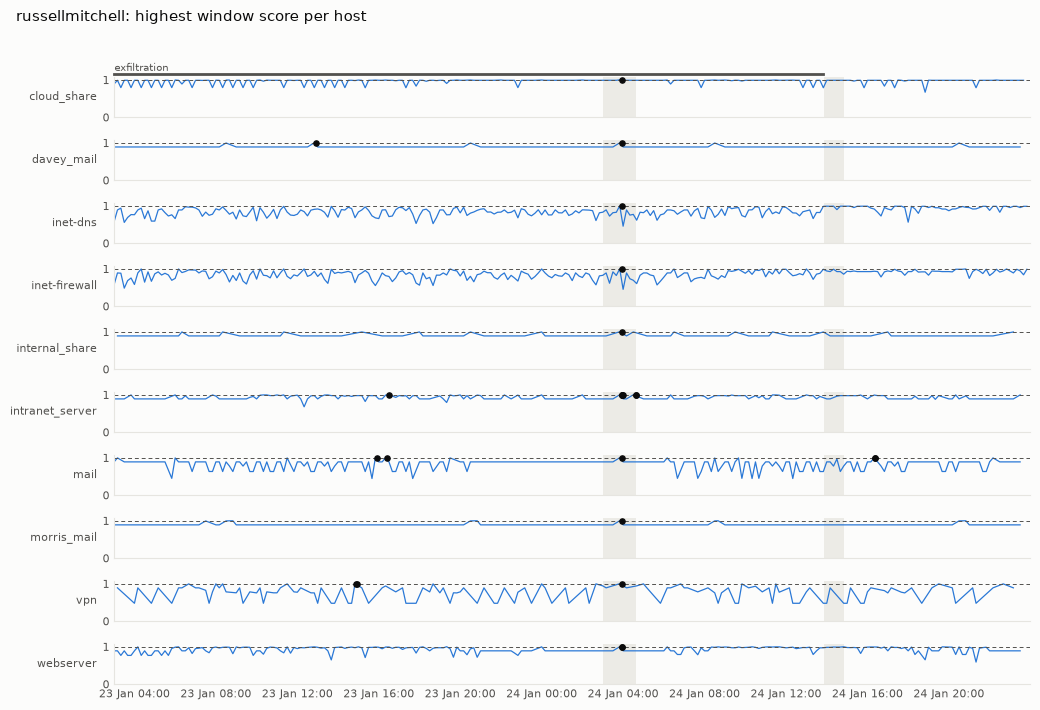

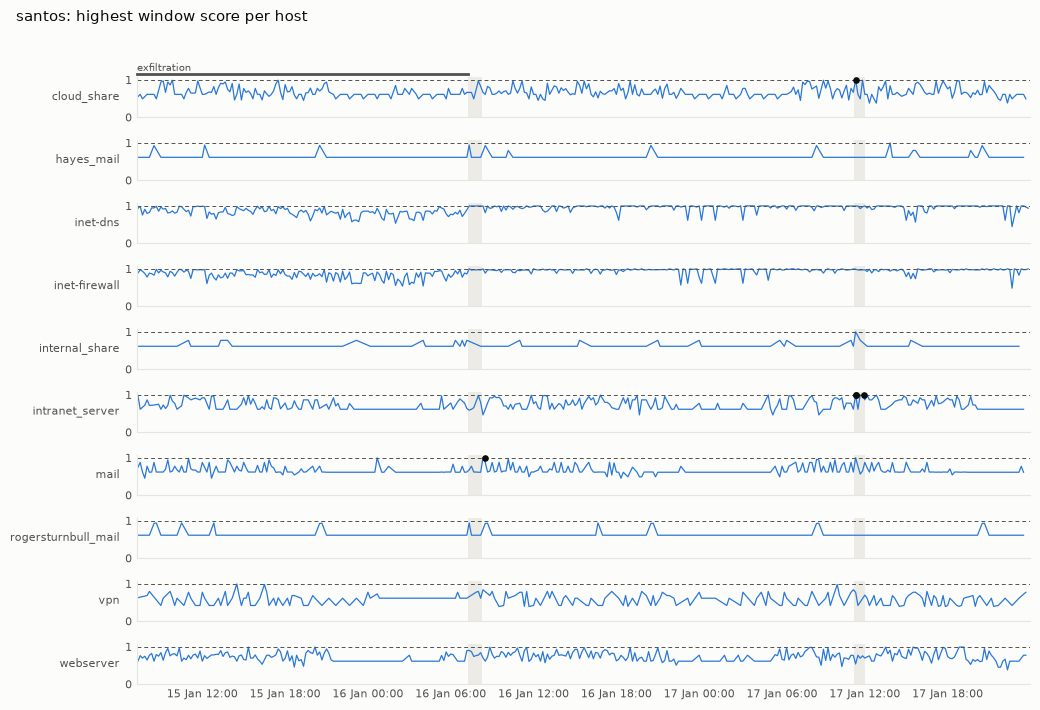

In [10]:
for name in TESTBEDS:
    table = scores[name]
    viz.plot_score_timeline(
        table[table["period"] == "eval"],
        intervals[name],
        settings.ml.q,
        f"{name}: highest window score per host",
        figures / f"m5_score_timeline_{name}.png",
    )
    plt.show()

## 10. Windows in two dimensions

All attack windows and up to 5,000 sampled normal windows of the evaluation period, colored by phase (§6.8). Features differ per log type, so each figure shows one log type. These two hold most phases.

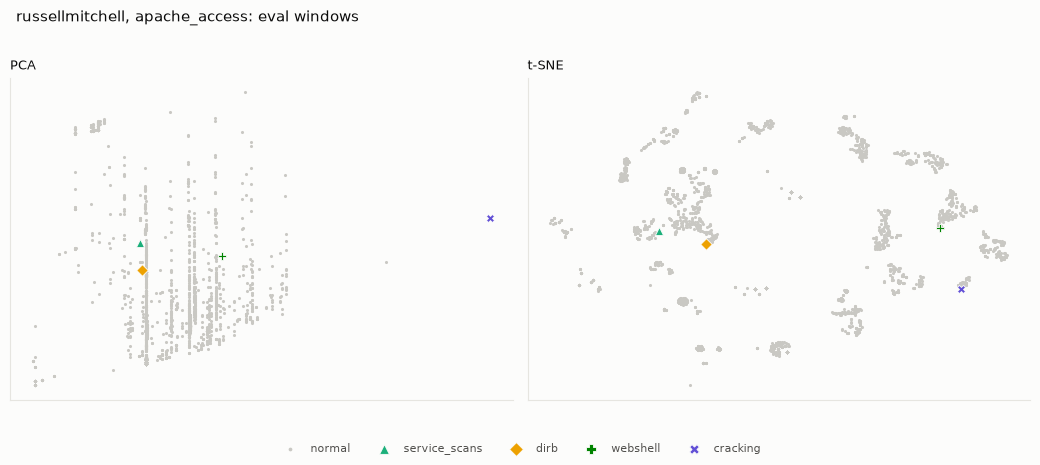

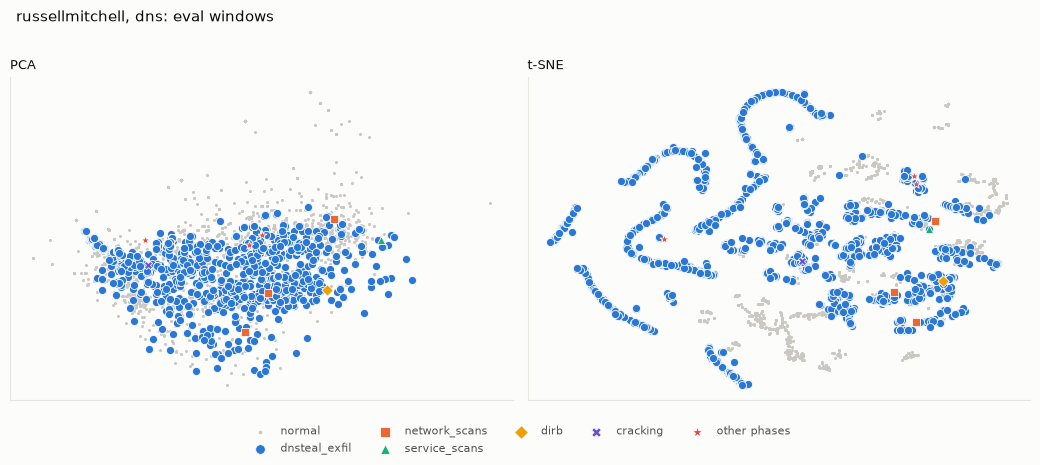

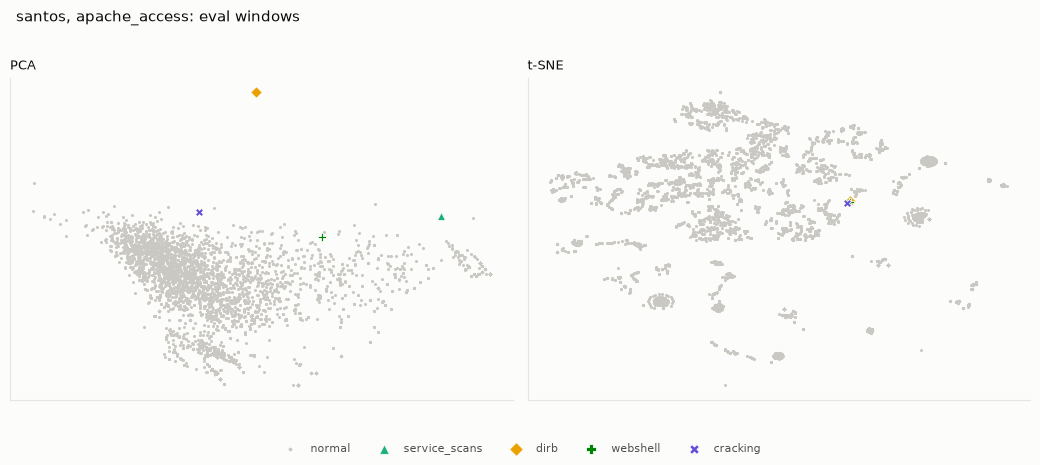

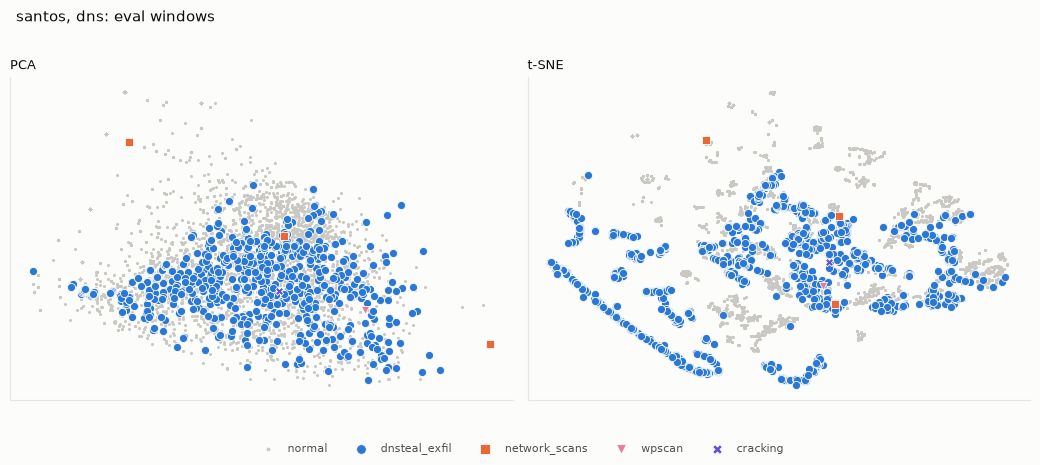

In [11]:
for name in TESTBEDS:
    for log_type in ("apache_access", "dns"):
        matrix, phases = embedding_inputs(name, log_type, contexts[name].truth, settings)
        viz.plot_window_embedding(
            matrix,
            phases,
            f"{name}, {log_type}: eval windows",
            settings.seed,
            figures / f"m5_embedding_{log_type}_{name}.png",
        )
        plt.show()

## 11. Supervised reference: audit

M6 starts with a read-only audit: nothing here fits a model or scores santos. The full tables are in `reports/audit_m6.md`. Two of them decided the design.

The first shows how few attack windows exist outside `dns`. Attacks last minutes, so thousands of labeled lines fall into a handful of one-minute windows.


In [12]:
from logtriage.eval.supervised_audit import audit
from logtriage.eval.viz import plot_feature_importance

results_dir = settings.paths.reports_dir / "results"
audit_tables = audit(settings)
counts = audit_tables["Windows per period"]
show(
    "Windows and attack windows per period",
    counts.pivot_table(
        index=["testbed", "log_type"], columns="period", values=["windows", "attack"]
    )
    .reindex(columns=["fit", "calib", "eval"], level=1)
    .astype(int),
)
show(
    "Both classes in 5 equal-count time blocks, russellmitchell calib and eval",
    audit_tables["Classes in 5 equal-count time blocks, russellmitchell calib and eval"].set_index(
        "log_type"
    ),
)

**Windows and attack windows per period**

attack             windows            
period                           fit calib  eval     fit calib  eval
testbed         log_type                                            
russellmitchell apache_access      0     0     4    4172  1264  3458
                audit              0     0     3    1393   209  1514
                auth               0     0     2    1136   272  1249
                dns             2448   613  2092    4896  1226  4855
                vpn                0     0     1     119    24   157
santos          apache_access      0     0     4    1832    83  5632
                audit              0     0     2     993   164  2730
                auth               0     0     1     692   176  1798
                dns             1501   375  1446    3002   750  5949
                vpn                0     0     1      77     7   227

**Both classes in 5 equal-count time blocks, russellmitchell calib and eval**

,windows,positives,negatives,positives_per_block,negatives_per_block
log_type,,,,,
apache_access,4722,4,4718,0/0/0/4/0,945/945/944/940/944
audit,1723,3,1720,0/0/0/3/0,345/345/345/341/344
auth,1521,2,1519,0/0/0/2/0,305/304/304/302/304
dns,3048,2705,343,610/610/610/609/266,0/0/0/0/343
vpn,181,1,180,0/0/0/1/0,37/36/36/35/36


Only `dns` reaches the 5 dev positives a model needs (D37). `apache_access`, `audit`, `auth` and `vpn` have 4, 3, 2 and 1, within minutes of each other, so they are reported as n/a with no fallback.

`dns` has the opposite problem. All 343 negatives come after the last positive, so plain contiguous blocks put them in one block, and holding it out leaves training with no negative. Blocks are therefore cut per class (D37).

## 12. Dev thresholds

Out-of-fold predictions on russellmitchell, written and committed before santos was scored (D39).


In [13]:
oof = pd.read_csv(results_dir / "supervised_dev_oof.csv")
columns = [
    "variant",
    "log_type",
    "model",
    "status",
    "windows",
    "positives",
    "negatives",
    "k_used",
    "threshold",
    "oof_precision",
    "oof_recall",
    "oof_f1",
    "oof_pr_auc",
]
show("Dev OOF", oof[columns].round(4).fillna("n/a").set_index(["variant", "log_type", "model"]))

/var/folders/3p/5dvxh87n5b7_1k_xjc93wprr0000gn/T/ipykernel_39401/3107641775.py:17: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  show("Dev OOF", oof[columns].round(4).fillna("n/a").set_index(["variant", "log_type", "model"]))


**Dev OOF**

status  windows  positives  \
variant         log_type      model                                      
calib_eval      apache_access rf     not_trainable     4722          4   
                              xgb    not_trainable     4722          4   
                audit         rf     not_trainable     1723          3   
                              xgb    not_trainable     1723          3   
                auth          rf     not_trainable     1521          2   
                              xgb    not_trainable     1521          2   
                dns           rf           trained     3048       2705   
                              xgb          trained     3048       2705   
                vpn           rf     not_trainable      181          1   
                              xgb    not_trainable      181          1   
all_dev_periods apache_access rf     not_trainable     8894          4   
                              xgb    not_trainable     8894          4   
                audit         rf     not_trainable     3116          3   
                              xgb    not_trainable     3116          3   
                auth          rf     not_trainable     2657          2   
                              xgb    not_trainable     2657          2   
                dns           rf           trained     5496       5153   
                              xgb          trained     5496       5153   
                vpn           rf     not_trainable      300          1   
                              xgb    not_trainable      300          1   

                                     negatives  k_used threshold  \
variant         log_type      model                                
calib_eval      apache_access rf          4718       0       n/a   
                              xgb         4718       0       n/a   
                audit         rf          1720       0       n/a   
                              xgb         1720       0       n/a   
                auth          rf          1519       0       n/a   
                              xgb         1519       0       n/a   
                dns           rf           343       5    0.8667   
                              xgb          343       5    0.9957   
                vpn           rf           180       0       n/a   
                              xgb          180       0       n/a   
all_dev_periods apache_access rf          8890       0       n/a   
                              xgb         8890       0       n/a   
                audit         rf          3113       0       n/a   
                              xgb         3113       0       n/a   
                auth          rf          2655       0       n/a   
                              xgb         2655       0       n/a   
                dns           rf           343       5    0.9133   
                              xgb          343       5    0.9957   
                vpn           rf           299       0       n/a   
                              xgb          299       0       n/a   

                                    oof_precision oof_recall  oof_f1  \
variant         log_type      model                                    
calib_eval      apache_access rf              n/a        n/a     n/a   
                              xgb             n/a        n/a     n/a   
                audit         rf              n/a        n/a     n/a   
                              xgb             n/a        n/a     n/a   
                auth          rf              n/a        n/a     n/a   
                              xgb             n/a        n/a     n/a   
                dns           rf           0.9996        1.0  0.9998   
                              xgb          0.9993     0.9989  0.9991   
                vpn           rf              n/a        n/a     n/a   
                              xgb             n/a        n/a     n/a   
all_dev_periods apache_access rf              n/a     

Dev OOF is close to perfect, and it is optimistic. The dev series changes class once, so all negatives come from one evening.

## 13. Santos: supervised reference next to the ensemble

Primary numbers, label-ambiguous windows left out (D17). `dns` has its own row because of the contaminated baseline (D16). n/a means no model: fewer than 5 dev positives, or for `pooled`, no model for every type (D38). An empty precision or F1 of the ensemble means it flagged nothing, which is a measured result and not n/a.

`pooled_trained` compares all three methods on the same windows. Only `dns` has a model, so that row equals the `dns` row and says nothing about the other four types. Pooled PR-AUC would mix uncalibrated per-type probabilities; with one type this has no effect today.


In [14]:
santos = pd.read_csv(results_dir / "supervised_santos.csv")
metric_columns = ["pr_auc", "precision", "recall", "f1"]


def santos_table(analysis: str, scopes: list[str] | None = None) -> pd.DataFrame:
    """Shape one analysis of the santos results, with n/a where there is no model."""
    table = santos[santos["analysis"] == analysis].copy()
    if scopes:
        table = table[table["scope"].isin(scopes)]
    no_model = table["status"] != "ok"
    table[metric_columns] = table[metric_columns].round(4).astype(object)
    table.loc[no_model, metric_columns] = "n/a"
    table["attack_share"] = table["attack_share"].round(4)
    kept = ["scope", "method", "windows", "n_pos", "attack_share", *metric_columns]
    return table[[*kept, "flagged", "true_positives"]].set_index(["scope", "method"])


show("Santos, primary", santos_table("primary"))

**Santos, primary**

windows  n_pos  attack_share  pr_auc precision  \
scope          method                                                     
apache_access  ensemble     5632      4        0.0007  0.8167    0.6667   
               rf           5632      4        0.0007     n/a       n/a   
               xgb          5632      4        0.0007     n/a       n/a   
audit          ensemble     2730      2        0.0007  0.5053       0.5   
               rf           2730      2        0.0007     n/a       n/a   
               xgb          2730      2        0.0007     n/a       n/a   
auth           ensemble     1798      1        0.0006   0.125       NaN   
               rf           1798      1        0.0006     n/a       n/a   
               xgb          1798      1        0.0006     n/a       n/a   
dns            ensemble     2952   1446        0.4898  0.3414       NaN   
               rf           2952   1446        0.4898   0.999    0.9979   
               xgb          2952   1446        0.4898  0.9941    0.9959   
vpn            ensemble      227      1        0.0044     0.2       NaN   
               rf            227      1        0.0044     n/a       n/a   
               xgb           227      1        0.0044     n/a       n/a   
pooled         ensemble    13339   1454        0.1090  0.1168       0.6   
               rf          13339   1454        0.1090     n/a       n/a   
               xgb         13339   1454        0.1090     n/a       n/a   
pooled_trained ensemble     2952   1446        0.4898  0.3414       NaN   
               rf           2952   1446        0.4898   0.999    0.9979   
               xgb          2952   1446        0.4898  0.9941    0.9959   

                         recall      f1  flagged  true_positives  
scope          method                                             
apache_access  ensemble     0.5  0.5714      3.0             2.0  
               rf           n/a     n/a      NaN             NaN  
               xgb          n/a     n/a      NaN             NaN  
audit          ensemble     0.5     0.5      2.0             1.0  
               rf           n/a     n/a      NaN             NaN  
               xgb          n/a     n/a      NaN             NaN  
auth           ensemble     0.0     NaN      0.0             0.0  
               rf           n/a     n/a      NaN             NaN  
               xgb          n/a     n/a      NaN             NaN  
dns            ensemble     0.0     NaN      0.0             0.0  
               rf        0.9965  0.9972   1444.0          1441.0  
               xgb       0.9965  0.9962   1447.0          1441.0  
vpn            ensemble     0.0     NaN      0.0             0.0  
               rf           n/a     n/a      NaN             NaN  
               xgb          n/a     n/a      NaN             NaN  
pooled         ensemble  0.0021  0.0041      5.0             3.0  
               rf           n/a     n/a      NaN             NaN  
               xgb          n/a     n/a      NaN             NaN  
pooled_trained ensemble     0.0     NaN      0.0             0.0  
               rf        0.9965  0.9972   1444.0          1441.0  
               xgb       0.9965  0.9962   1447.0          1441.0

On `dns` the reference finds the tunnel almost perfectly, where the ensemble flags nothing and ranks below the attack share. That gap is about what each method is told, not about model quality. The tunnel is part of the training baseline (D16), so the ensemble is taught that it is normal, and the labels here say it is an attack.

This is not an upper bound (§6.7), and for four of five types there is no supervised number at all, so it cannot say what labels would add there.

## 14. Feature importance

Impurity for RF and gain for XGBoost, from the primary models fit on dev.


**dns: top features**

importance
model feature                           
rf    max_label_entropy           0.3297
      max_label_len               0.2670
      mean_qname_len              0.1673
      mean_label_entropy          0.1000
      max_template_rarity         0.0292
      mean_template_rarity        0.0261
xgb   max_label_entropy           1.0000
      n_lines                     0.0000
      n_unseen_templates          0.0000
      ratio_unseen_templates      0.0000
      mean_template_rarity        0.0000
      max_template_rarity         0.0000

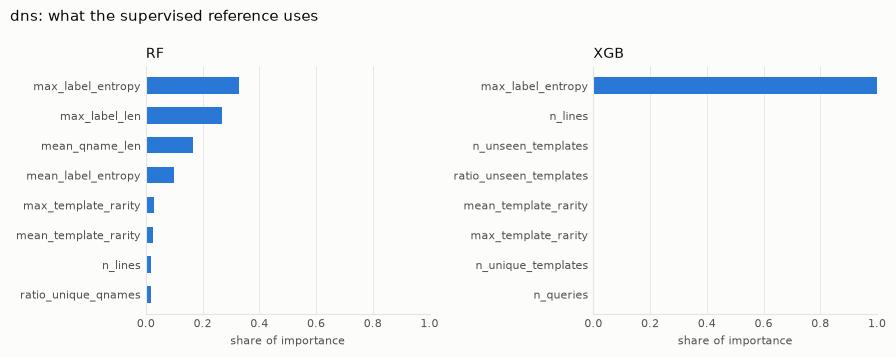

In [15]:
importance = pd.read_csv(results_dir / "supervised_importance.csv")
show(
    "dns: top features",
    importance.groupby("model").head(6).round(4).set_index(["model", "feature"])[["importance"]],
)
plot_feature_importance(
    importance[importance["log_type"] == "dns"],
    "dns: what the supervised reference uses",
    8,
    figures / "m6_feature_importance_dns.png",
)
plt.show()

XGBoost gives all its gain to `max_label_entropy`, so it uses a single feature, and every score in the error file below is one of two values. RF spreads the same signal over correlated name features. The rule transfers because the tunnel labels are long and random on both testbeds, even though their length differs (median 35 characters on dev, 61 on santos).

## 15. What the models got wrong

Every wrong window outside the label-ambiguous ones. The file comes from the frozen models; see D40 for how it was produced.


In [16]:
errors = pd.read_csv(results_dir / "supervised_santos_errors.csv")
show("Santos dns errors", errors.round(4).set_index(["window_start", "kind"]))

**Santos dns errors**

,,host,log_type,phases,n_queries,mean_qname_len,max_label_len,max_label_entropy,rf_score,rf_flag,xgb_score,xgb_flag
window_start,kind,,,,,,,,,,,
2022-01-16 09:31:00+00:00,false_positive,inet-firewall,dns,NaN,110,23.3545,40,4.5994,0.8167,False,0.9971,True
2022-01-16 10:53:00+00:00,false_positive,inet-firewall,dns,NaN,41,20.8049,39,4.6313,0.8133,False,0.9971,True
2022-01-16 10:57:00+00:00,false_positive,inet-firewall,dns,NaN,89,21.5730,39,4.6119,0.8733,True,0.9971,True
2022-01-16 11:03:00+00:00,false_positive,inet-firewall,dns,NaN,16,26.6250,39,4.5607,0.9467,True,0.9971,True
2022-01-16 14:02:00+00:00,false_positive,inet-firewall,dns,NaN,127,20.8583,40,4.6826,0.8300,False,0.9971,True
2022-01-17 11:15:00+00:00,missed,inet-firewall,dns,network_scans,2,25.0000,7,2.5216,0.0067,False,0.0029,False
2022-01-17 11:16:00+00:00,missed,inet-firewall,dns,network_scans,17,25.5882,7,2.5216,0.0000,False,0.0029,False
2022-01-17 11:18:00+00:00,false_positive,inet-firewall,dns,NaN,174,23.5287,39,4.6313,0.9033,True,0.9971,True
2022-01-17 11:21:00+00:00,missed,inet-firewall,dns,network_scans service_scans,290,22.6034,39,4.4581,0.6767,False,0.0029,False


The misses are the 5 attack windows without exfiltration: scans on 01-17, after the tunnel stopped, with ordinary names. The 1,441 hits are exactly the exfiltration-only windows. So this is a tunnel detector, and it has not learned scans in DNS: on dev only 9 of 2,705 positives are not exfiltration-only.

The false positives are ordinary windows with one long, random name (39 or 40 characters, entropy above 4.5), the same shape as the rule.

## 16. Secondary results

Clearly secondary: these were used for no selection. Each shows `dns` and the pooled rows.


In [17]:
scopes = ["dns", "pooled", "pooled_trained"]
for name, title in {
    "secondary_without_exfil_only": "Without exfiltration-only windows",
    "secondary_with_ambiguous": "With label-ambiguous windows counted as normal",
    "secondary_all_dev_periods": "Trained on all dev periods",
}.items():
    show(f"Santos, secondary: {title}", santos_table(name, scopes))

**Santos, secondary: Without exfiltration-only windows**

windows  n_pos  attack_share  pr_auc precision  \
scope          method                                                     
dns            ensemble     1511      5        0.0033  0.0141       NaN   
               rf           1511      5        0.0033  0.0272       0.0   
               xgb          1511      5        0.0033  0.0033       0.0   
pooled         ensemble    11898     13        0.0011   0.269       0.6   
               rf          11898     13        0.0011     n/a       n/a   
               xgb         11898     13        0.0011     n/a       n/a   
pooled_trained ensemble     1511      5        0.0033  0.0141       NaN   
               rf           1511      5        0.0033  0.0272       0.0   
               xgb          1511      5        0.0033  0.0033       0.0   

                         recall      f1  flagged  true_positives  
scope          method                                             
dns            ensemble     0.0     NaN      0.0             0.0  
               rf           0.0     NaN      3.0             0.0  
               xgb          0.0     NaN      6.0             0.0  
pooled         ensemble  0.2308  0.3333      5.0             3.0  
               rf           n/a     n/a      NaN             NaN  
               xgb          n/a     n/a      NaN             NaN  
pooled_trained ensemble     0.0     NaN      0.0             0.0  
               rf           0.0     NaN      3.0             0.0  
               xgb          0.0     NaN      6.0             0.0

**Santos, secondary: With label-ambiguous windows counted as normal**

windows  n_pos  attack_share  pr_auc precision  \
scope          method                                                     
dns            ensemble     5949   1446        0.2431  0.1711       NaN   
               rf           5949   1446        0.2431  0.5861    0.4993   
               xgb          5949   1446        0.2431   0.497    0.4979   
pooled         ensemble    16336   1454        0.0890  0.0854       0.6   
               rf          16336   1454        0.0890     n/a       n/a   
               xgb         16336   1454        0.0890     n/a       n/a   
pooled_trained ensemble     5949   1446        0.2431  0.1711       NaN   
               rf           5949   1446        0.2431  0.5861    0.4993   
               xgb          5949   1446        0.2431   0.497    0.4979   

                         recall      f1  flagged  true_positives  
scope          method                                             
dns            ensemble     0.0     NaN      0.0             0.0  
               rf        0.9965  0.6653   2886.0          1441.0  
               xgb       0.9965  0.6641   2894.0          1441.0  
pooled         ensemble  0.0021  0.0041      5.0             3.0  
               rf           n/a     n/a      NaN             NaN  
               xgb          n/a     n/a      NaN             NaN  
pooled_trained ensemble     0.0     NaN      0.0             0.0  
               rf        0.9965  0.6653   2886.0          1441.0  
               xgb       0.9965  0.6641   2894.0          1441.0

**Santos, secondary: Trained on all dev periods**

windows  n_pos  attack_share  pr_auc precision  \
scope          method                                                     
dns            ensemble     2952   1446        0.4898  0.3414       NaN   
               rf           2952   1446        0.4898  0.9994    0.9986   
               xgb          2952   1446        0.4898  0.9941    0.9959   
pooled         ensemble    13339   1454        0.1090  0.1168       0.6   
               rf          13339   1454        0.1090     n/a       n/a   
               xgb         13339   1454        0.1090     n/a       n/a   
pooled_trained ensemble     2952   1446        0.4898  0.3414       NaN   
               rf           2952   1446        0.4898  0.9994    0.9986   
               xgb          2952   1446        0.4898  0.9941    0.9959   

                         recall      f1  flagged  true_positives  
scope          method                                             
dns            ensemble     0.0     NaN      0.0             0.0  
               rf        0.9965  0.9976   1443.0          1441.0  
               xgb       0.9965  0.9962   1447.0          1441.0  
pooled         ensemble  0.0021  0.0041      5.0             3.0  
               rf           n/a     n/a      NaN             NaN  
               xgb          n/a     n/a      NaN             NaN  
pooled_trained ensemble     0.0     NaN      0.0             0.0  
               rf        0.9965  0.9976   1443.0          1441.0  
               xgb       0.9965  0.9962   1447.0          1441.0

Without exfiltration-only windows the reference finds nothing on `dns`: 0 of 5 flagged, PR-AUC 0.027 (RF) and 0.003 (XGBoost) at attack share 0.003, on 5 positives. With label-ambiguous windows precision falls to about 0.5, because `inet-dns` holds unlabeled copies of the tunnel: RF flags 1,442 of those windows, 3 of them after the tunnel stopped. These are the windows D17 warned about, and they are real detections counted as false. Training on all periods changes almost nothing, since the fit period adds only positives.

## 17. Window-level phases

Secondary, and **not comparable to primary phase recall**: a phase counts here if at least one flagged attack window holds it, with no incident step. The ensemble covers five log types and the models only `dns`, so an extra row shows the ensemble on `dns` alone.


In [18]:
phases = pd.read_csv(results_dir / "supervised_santos_phases.csv").fillna("")
show("Santos, window-level phases", phases.set_index(["method", "log_types", "phases_scope"]))

**Santos, window-level phases**

phases_flagged  \
method   log_types                        phases_scope                    
ensemble apache_access audit auth dns vpn all_phases                  5   
                                          without_exfil               5   
         dns                              all_phases                  0   
                                          without_exfil               0   
rf       dns                              all_phases                  1   
                                          without_exfil               0   
xgb      dns                              all_phases                  1   
                                          without_exfil               0   

                                                         phases  \
method   log_types                        phases_scope            
ensemble apache_access audit auth dns vpn all_phases          9   
                                          without_exfil       8   
         dns                              all_phases          9   
                                          without_exfil       8   
rf       dns                              all_phases          9   
                                          without_exfil       8   
xgb      dns                              all_phases          9   
                                          without_exfil       8   

                                                                                                   flagged  \
method   log_types                        phases_scope                                                       
ensemble apache_access audit auth dns vpn all_phases     service_scans dirb wpscan webshell privilege_e...   
                                          without_exfil  service_scans dirb wpscan webshell privilege_e...   
         dns                              all_phases                                                         
                                          without_exfil                                                      
rf       dns                              all_phases                                         dnsteal_exfil   
                                          without_exfil                                                      
xgb      dns                              all_phases                                         dnsteal_exfil   
                                          without_exfil                                                      

                                                                                               not_flagged  
method   log_types                        phases_scope                                                      
ensemble apache_access audit auth dns vpn all_phases     dnsteal_exfil service_stop network_scans cracking  
                                          without_exfil                service_stop network_scans cracking  
         dns                              all_phases     dnsteal_exfil service_stop network_scans servi...  
                                          without_exfil  service_stop network_scans service_scans dirb ...  
rf       dns                              all_phases     service_stop network_scans service_scans dirb ...  
                                          without_exfil  service_stop network_scans service_scans dirb ...  
xgb      dns                              all_phases     service_stop network_scans service_scans dirb ...  
                                          without_exfil  service_stop network_scans service_scans dirb ...

The reference flags `dnsteal_exfil` and no other phase. It finds the one phase the ensemble cannot, and misses the five the ensemble does find, so the two see different things. Neither reaches 8 of 9 alone.
